# Génération des Visualisations pour l'Article

Ce notebook génère les 6 visualisations nécessaires pour l'article LaTeX.

**IMPORTANT:** Exécutez d'abord `prediction_medicaments_complete.ipynb` (variables en mémoire), ou chargez les CSV de `models/` / `outputs/` pour les graphiques de comparaison.

## Visualisations à générer:
1. Graphique en barres MAPE - Comparaison des modèles
2. Courbes prédictions vs réelles - MLR et Hybrid
3. SHAP summary plot - Feature importance
4. Feature importance MLR - Coefficients normalisés
5. Matrice de corrélation - Features importantes
6. Série temporelle - Distribution de la consommation


## 1. Importation des bibliothèques


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import warnings
warnings.filterwarnings('ignore')

# Configuration pour des graphiques de qualité publication
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette("husl")

# Configuration des paramètres matplotlib pour haute qualité
plt.rcParams['figure.dpi'] = 300
plt.rcParams['savefig.dpi'] = 300
plt.rcParams['font.size'] = 11
plt.rcParams['axes.labelsize'] = 12
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['xtick.labelsize'] = 10
plt.rcParams['ytick.labelsize'] = 10
plt.rcParams['legend.fontsize'] = 10
plt.rcParams['figure.titlesize'] = 16

# Créer le dossier pour sauvegarder les images
import os
os.makedirs('../figures', exist_ok=True)

print("✓ Bibliothèques importées")
print("✓ Dossier 'figures' créé pour sauvegarder les images")


✓ Bibliothèques importées
✓ Dossier 'figures' créé pour sauvegarder les images


## 2. Vérification des variables nécessaires


In [2]:
# Vérifier que les variables nécessaires existent
required_vars = ['y_test', 'train', 'test']
missing_vars = []

for var in required_vars:
    if var not in locals() and var not in globals():
        missing_vars.append(var)

if missing_vars:
    print("⚠️ Variables manquantes:", missing_vars)
    print("   Veuillez exécuter le notebook principal d'abord.")
else:
    print("✓ Toutes les variables nécessaires sont disponibles")


⚠️ Variables manquantes: ['y_test', 'train', 'test']
   Veuillez exécuter le notebook principal d'abord.


## 3. Visualisation 1: Graphique en barres MAPE - Comparaison des modèles


✓ Image sauvegardée: figures/model_comparison_mape.png


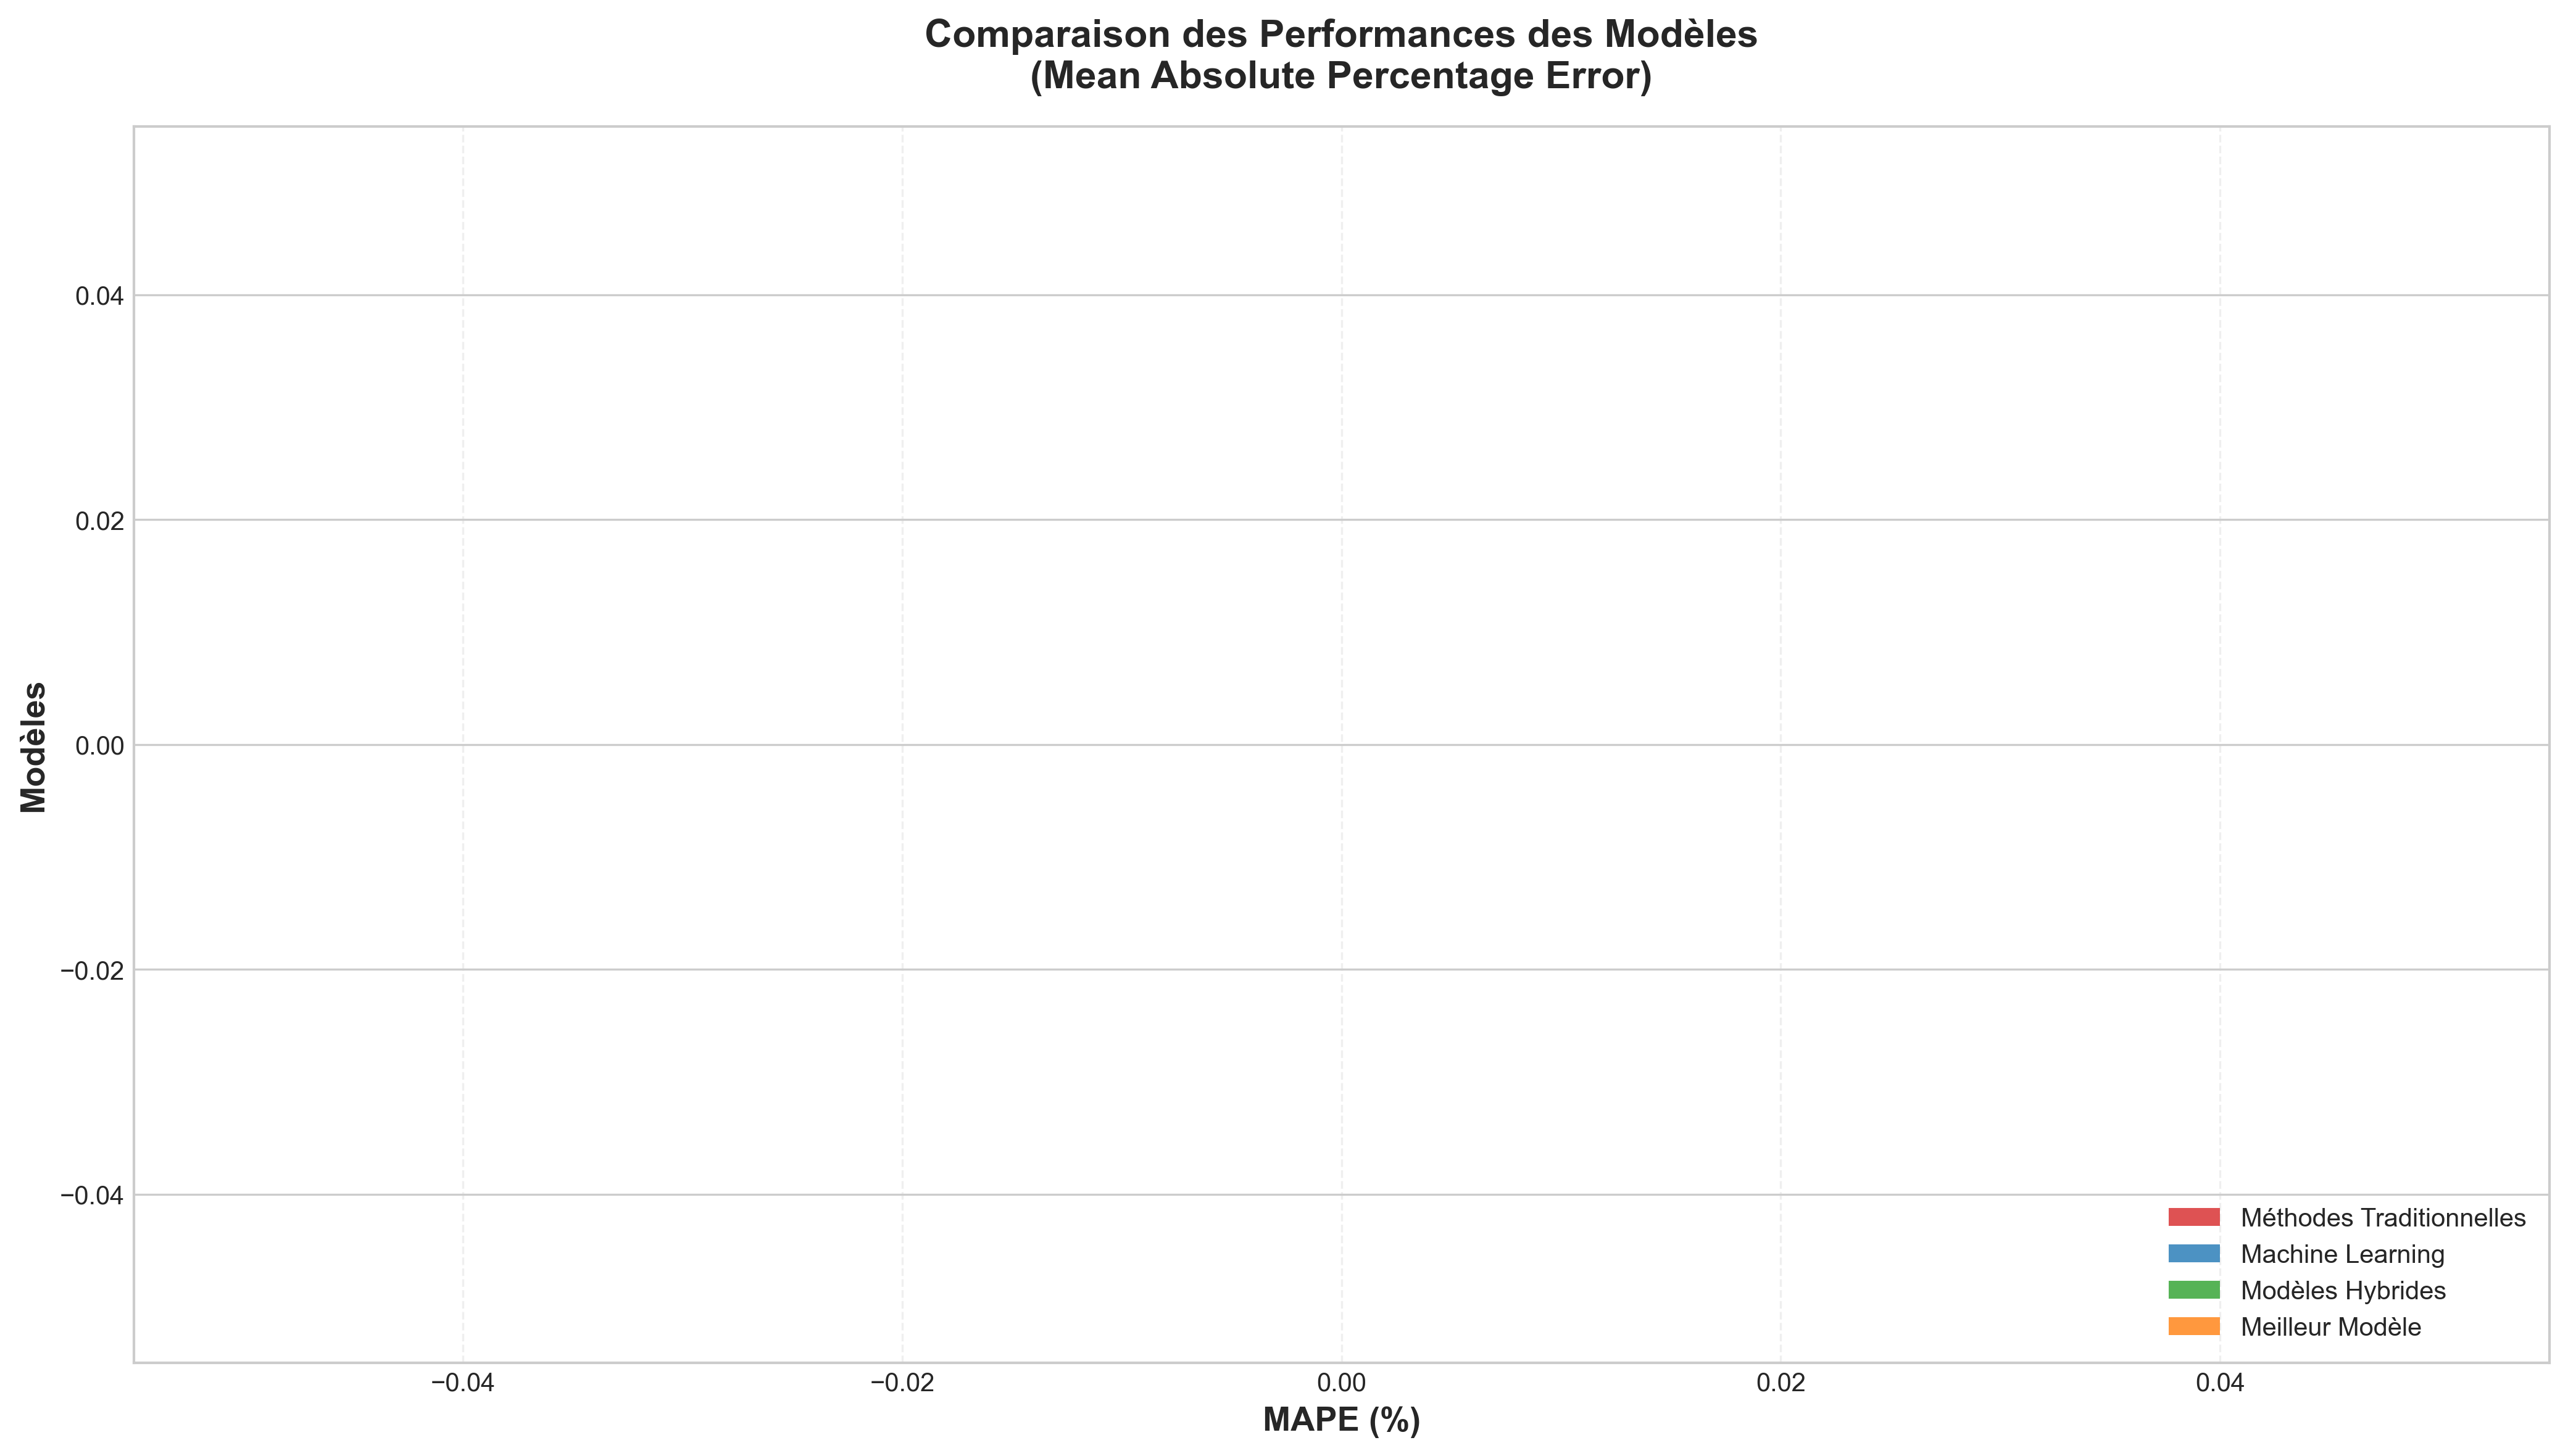

In [3]:
def calculate_mape(y_true, y_pred):
    """Calcule le MAPE"""
    mask = y_true != 0
    if mask.sum() == 0:
        return np.nan
    return np.mean(np.abs((y_true[mask] - y_pred[mask]) / y_true[mask])) * 100

# Collecter les résultats de tous les modèles
models_mape = {}

# Modèles traditionnels
if 'lta_pred' in locals() and lta_pred is not None:
    models_mape['LTA'] = calculate_mape(y_test.values, lta_pred)
if 'ses_pred' in locals() and ses_pred is not None:
    models_mape['SES'] = calculate_mape(y_test.values, ses_pred)
if 'des_pred' in locals() and des_pred is not None:
    models_mape['DES'] = calculate_mape(y_test.values, des_pred)
if 'arima_pred' in locals() and arima_pred is not None:
    arima_clean = np.array(arima_pred).flatten()
    if len(arima_clean) == len(y_test):
        if np.isnan(arima_clean).any():
            arima_clean = pd.Series(arima_clean).interpolate(method='linear').bfill().ffill().values
        models_mape['ARIMA'] = calculate_mape(y_test.values, arima_clean)

# Modèles ML
if 'mlr_pred_test' in locals() and mlr_pred_test is not None:
    models_mape['MLR'] = calculate_mape(y_test.values, mlr_pred_test)
if 'rf_pred_test' in locals() and rf_pred_test is not None:
    models_mape['Random Forest'] = calculate_mape(y_test.values, rf_pred_test)
if 'xgb_pred_test' in locals() and xgb_pred_test is not None:
    models_mape['XGBoost'] = calculate_mape(y_test.values, xgb_pred_test)
if 'lstm_pred' in locals() and lstm_pred is not None:
    lstm_clean = np.array(lstm_pred).flatten()
    if len(lstm_clean) == len(y_test):
        if np.isnan(lstm_clean).any():
            lstm_clean = pd.Series(lstm_clean).interpolate(method='linear').bfill().ffill().values
        models_mape['LSTM'] = calculate_mape(y_test.values, lstm_clean)

# Modèles hybrides
if 'hybrid_pred' in locals() and hybrid_pred is not None:
    hybrid_clean = np.array(hybrid_pred).flatten()
    if len(hybrid_clean) == len(y_test):
        if np.isnan(hybrid_clean).any():
            hybrid_clean = pd.Series(hybrid_clean).interpolate(method='linear').bfill().ffill().values
        models_mape['Hybrid (MLR+DES)'] = calculate_mape(y_test.values, hybrid_clean)

# Créer le graphique
fig, ax = plt.subplots(figsize=(14, 8))

# Trier par MAPE
sorted_models = sorted(models_mape.items(), key=lambda x: x[1] if not np.isnan(x[1]) else np.inf)
models_names = [m[0] for m in sorted_models]
mape_values = [m[1] for m in sorted_models]

# Couleurs: rouge pour traditionnels, bleu pour ML, vert pour hybrides
colors = []
for name in models_names:
    if name in ['LTA', 'SES', 'DES', 'ARIMA']:
        colors.append('#d62728')  # Rouge
    elif 'Hybrid' in name:
        colors.append('#2ca02c')  # Vert
    else:
        colors.append('#1f77b4')  # Bleu

# Graphique en barres
bars = ax.barh(models_names, mape_values, color=colors, alpha=0.8, edgecolor='black', linewidth=1.2)

# Ajouter les valeurs sur les barres
for i, (name, value) in enumerate(zip(models_names, mape_values)):
    if not np.isnan(value):
        ax.text(value + 0.5, i, f'{value:.2f}%', 
                va='center', fontsize=10, fontweight='bold')

# Mettre en évidence les meilleurs modèles
if len(mape_values) > 0:
    best_idx = np.nanargmin(mape_values)
    bars[best_idx].set_color('#ff7f0e')  # Orange pour le meilleur
    bars[best_idx].set_edgecolor('darkorange')
    bars[best_idx].set_linewidth(2.5)

ax.set_xlabel('MAPE (%)', fontsize=13, fontweight='bold')
ax.set_ylabel('Modèles', fontsize=13, fontweight='bold')
ax.set_title('Comparaison des Performances des Modèles\n(Mean Absolute Percentage Error)', 
             fontsize=15, fontweight='bold', pad=15)
ax.grid(True, alpha=0.3, axis='x', linestyle='--')
if len(mape_values) > 0:
    ax.set_xlim(0, max([v for v in mape_values if not np.isnan(v)]) * 1.15)

# Légende
from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor='#d62728', alpha=0.8, label='Méthodes Traditionnelles'),
    Patch(facecolor='#1f77b4', alpha=0.8, label='Machine Learning'),
    Patch(facecolor='#2ca02c', alpha=0.8, label='Modèles Hybrides'),
    Patch(facecolor='#ff7f0e', alpha=0.8, label='Meilleur Modèle')
]
ax.legend(handles=legend_elements, loc='lower right', fontsize=10)

plt.tight_layout()
plt.savefig('../figures/model_comparison_mape.png', bbox_inches='tight', dpi=300)
print("✓ Image sauvegardée: figures/model_comparison_mape.png")
plt.show()


In [5]:
# Créer les indices temporels
if 'date' in test.columns:
    time_index = test['date'].iloc[:len(y_test)].values
    xlabel = 'Date'
else:
    time_index = np.arange(len(y_test))
    xlabel = 'Index temporel'

fig, axes = plt.subplots(2, 1, figsize=(16, 10))

# Graphique 1: MLR
ax1 = axes[0]
ax1.plot(time_index, y_test.values, label='Valeurs Réelles', 
         color='black', linewidth=2.5, alpha=0.9, zorder=10)

if 'mlr_pred_test' in locals() and mlr_pred_test is not None:
    mlr_clean = np.array(mlr_pred_test).flatten()
    if len(mlr_clean) != len(y_test):
        mlr_clean = mlr_clean[:len(y_test)]
    if np.isnan(mlr_clean).any():
        mlr_clean = pd.Series(mlr_clean).interpolate(method='linear').bfill().ffill().values
    
    ax1.plot(time_index, mlr_clean, label='Prédictions MLR', 
             color='#1f77b4', linestyle='--', linewidth=2, alpha=0.8)
    
    # Calculer les métriques
    mae_mlr = mean_absolute_error(y_test.values, mlr_clean)
    rmse_mlr = np.sqrt(mean_squared_error(y_test.values, mlr_clean))
    r2_mlr = r2_score(y_test.values, mlr_clean)
    mape_mlr = calculate_mape(y_test.values, mlr_clean)
    
    ax1.set_title(f'Multiple Linear Regression (MLR)\nMAE: {mae_mlr:.2f} | RMSE: {rmse_mlr:.2f} | R²: {r2_mlr:.4f} | MAPE: {mape_mlr:.2f}%', 
                 fontsize=13, fontweight='bold')

ax1.set_xlabel(xlabel, fontsize=12)
ax1.set_ylabel('Volume de Consommation', fontsize=12)
ax1.legend(loc='best', fontsize=11)
ax1.grid(True, alpha=0.3, linestyle='--')
if xlabel == 'Date':
    plt.setp(ax1.xaxis.get_majorticklabels(), rotation=45, ha='right')

# Graphique 2: Hybrid (MLR+DES)
ax2 = axes[1]
ax2.plot(time_index, y_test.values, label='Valeurs Réelles', 
         color='black', linewidth=2.5, alpha=0.9, zorder=10)

if 'hybrid_pred' in locals() and hybrid_pred is not None:
    hybrid_clean = np.array(hybrid_pred).flatten()
    if len(hybrid_clean) != len(y_test):
        hybrid_clean = hybrid_clean[:len(y_test)]
    if np.isnan(hybrid_clean).any():
        hybrid_clean = pd.Series(hybrid_clean).interpolate(method='linear').bfill().ffill().values
    
    ax2.plot(time_index, hybrid_clean, label='Prédictions Hybrid (MLR+DES)', 
             color='#2ca02c', linestyle='--', linewidth=2, alpha=0.8)
    
    # Calculer les métriques
    mae_hybrid = mean_absolute_error(y_test.values, hybrid_clean)
    rmse_hybrid = np.sqrt(mean_squared_error(y_test.values, hybrid_clean))
    r2_hybrid = r2_score(y_test.values, hybrid_clean)
    mape_hybrid = calculate_mape(y_test.values, hybrid_clean)
    
    ax2.set_title(f'Hybrid Model (MLR + DES)\nMAE: {mae_hybrid:.2f} | RMSE: {rmse_hybrid:.2f} | R²: {r2_hybrid:.4f} | MAPE: {mape_hybrid:.2f}%', 
                 fontsize=13, fontweight='bold')

ax2.set_xlabel(xlabel, fontsize=12)
ax2.set_ylabel('Volume de Consommation', fontsize=12)
ax2.legend(loc='best', fontsize=11)
ax2.grid(True, alpha=0.3, linestyle='--')
if xlabel == 'Date':
    plt.setp(ax2.xaxis.get_majorticklabels(), rotation=45, ha='right')

plt.tight_layout()
plt.savefig('../figures/predictions_vs_actual.png', bbox_inches='tight', dpi=300)
print("✓ Image sauvegardée: figures/predictions_vs_actual.png")
plt.show()


NameError: name 'test' is not defined

In [6]:
# Vérifier si SHAP est disponible et si le modèle MLR existe
try:
    import shap
    SHAP_AVAILABLE = True
except ImportError:
    SHAP_AVAILABLE = False
    print("⚠️ SHAP non disponible. Installation: pip install shap")

if SHAP_AVAILABLE and 'mlr_model' in locals() and 'X_test_mlr' in locals():
    try:
        # Utiliser LinearExplainer pour MLR (plus rapide et précis)
        explainer = shap.LinearExplainer(mlr_model, X_train_mlr)
        shap_values = explainer.shap_values(X_test_mlr[:min(100, len(X_test_mlr))])  # Limiter pour la vitesse
        
        # Créer le summary plot
        fig, ax = plt.subplots(figsize=(12, 8))
        shap.summary_plot(shap_values, X_test_mlr[:min(100, len(X_test_mlr))], 
                          feature_names=X_train_mlr.columns if hasattr(X_train_mlr, 'columns') else None,
                          show=False, plot_type='bar')
        
        plt.title('SHAP Feature Importance - Multiple Linear Regression', 
                 fontsize=14, fontweight='bold', pad=15)
        plt.tight_layout()
        plt.savefig('../figures/shap_summary.png', bbox_inches='tight', dpi=300)
        print("✓ Image sauvegardée: figures/shap_summary.png")
        plt.show()
        
    except Exception as e:
        print(f"⚠️ Erreur lors de la génération SHAP: {e}")
        print("   Création d'un graphique alternatif avec les coefficients MLR")
        
        # Alternative: utiliser les coefficients MLR
        if 'mlr_model' in locals() and hasattr(mlr_model, 'coef_'):
            coef = mlr_model.coef_
            feature_names = X_train_mlr.columns if hasattr(X_train_mlr, 'columns') else [f'Feature_{i}' for i in range(len(coef))]
            
            # Créer un DataFrame
            importance_df = pd.DataFrame({
                'Feature': feature_names,
                'Coefficient': coef,
                'Abs_Coefficient': np.abs(coef)
            }).sort_values('Abs_Coefficient', ascending=False).head(15)
            
            fig, ax = plt.subplots(figsize=(12, 8))
            ax.barh(importance_df['Feature'], importance_df['Coefficient'], 
                   color='steelblue', alpha=0.8, edgecolor='black')
            ax.set_xlabel('Coefficient Value', fontsize=12, fontweight='bold')
            ax.set_ylabel('Features', fontsize=12, fontweight='bold')
            ax.set_title('MLR Feature Importance (Coefficients)', 
                        fontsize=14, fontweight='bold', pad=15)
            ax.grid(True, alpha=0.3, axis='x', linestyle='--')
            plt.tight_layout()
            plt.savefig('../figures/shap_summary.png', bbox_inches='tight', dpi=300)
            print("✓ Image sauvegardée: figures/shap_summary.png (alternative avec coefficients)")
            plt.show()
else:
    print("⚠️ SHAP ou modèle MLR non disponible. Passage à la visualisation suivante.")


⚠️ SHAP non disponible. Installation: pip install shap
⚠️ SHAP ou modèle MLR non disponible. Passage à la visualisation suivante.


## 6. Visualisation 4: Feature Importance MLR - Coefficients normalisés


In [7]:
if 'mlr_model' in locals() and 'X_train_mlr' in locals():
    # Obtenir les coefficients
    coef = mlr_model.coef_
    
    # Obtenir les noms des features
    if hasattr(X_train_mlr, 'columns'):
        feature_names = X_train_mlr.columns.tolist()
    else:
        feature_names = [f'Feature_{i}' for i in range(len(coef))]
    
    # Normaliser les coefficients (utiliser les écarts-types des features)
    if hasattr(X_train_mlr, 'std'):
        std_features = X_train_mlr.std().values
    else:
        std_features = np.std(X_train_mlr, axis=0)
    
    # Coefficients standardisés = coefficient * std(feature)
    standardized_coef = coef * std_features
    
    # Créer un DataFrame
    importance_df = pd.DataFrame({
        'Feature': feature_names,
        'Coefficient': coef,
        'Standardized_Coefficient': standardized_coef,
        'Abs_Standardized': np.abs(standardized_coef)
    }).sort_values('Abs_Standardized', ascending=False)
    
    # Prendre les top 15
    top_features = importance_df.head(15)
    
    # Créer le graphique
    fig, ax = plt.subplots(figsize=(12, 8))
    
    # Couleurs selon le signe
    colors = ['#d62728' if x < 0 else '#2ca02c' for x in top_features['Standardized_Coefficient']]
    
    bars = ax.barh(top_features['Feature'], top_features['Standardized_Coefficient'], 
                   color=colors, alpha=0.8, edgecolor='black', linewidth=1.2)
    
    # Ajouter les valeurs
    for i, (idx, row) in enumerate(top_features.iterrows()):
        ax.text(row['Standardized_Coefficient'] + (max(top_features['Standardized_Coefficient']) * 0.02), 
                i, f"{row['Standardized_Coefficient']:.3f}", 
                va='center', fontsize=9)
    
    ax.axvline(x=0, color='black', linestyle='-', linewidth=1)
    ax.set_xlabel('Coefficient Standardisé', fontsize=12, fontweight='bold')
    ax.set_ylabel('Features', fontsize=12, fontweight='bold')
    ax.set_title('Feature Importance - Multiple Linear Regression\n(Coefficients Standardisés)', 
                fontsize=14, fontweight='bold', pad=15)
    ax.grid(True, alpha=0.3, axis='x', linestyle='--')
    
    # Légende
    from matplotlib.patches import Patch
    legend_elements = [
        Patch(facecolor='#2ca02c', alpha=0.8, label='Impact Positif'),
        Patch(facecolor='#d62728', alpha=0.8, label='Impact Négatif')
    ]
    ax.legend(handles=legend_elements, loc='lower right', fontsize=10)
    
    plt.tight_layout()
    plt.savefig('../figures/feature_importance_mlr.png', bbox_inches='tight', dpi=300)
    print("✓ Image sauvegardée: figures/feature_importance_mlr.png")
    plt.show()
    
    # Afficher le tableau
    print("\nTop 15 Features par Importance:")
    print(top_features[['Feature', 'Standardized_Coefficient']].to_string(index=False))
else:
    print("⚠️ Modèle MLR ou données non disponibles")


⚠️ Modèle MLR ou données non disponibles


## 7. Visualisation 5: Matrice de corrélation - Features importantes


In [ ]:
# Sélectionner les features importantes pour la corrélation
if 'X_train_mlr' in locals() and 'train' in locals():
    # Obtenir les features et la target
    if hasattr(X_train_mlr, 'columns'):
        feature_cols = X_train_mlr.columns.tolist()
    else:
        feature_cols = [f'Feature_{i}' for i in range(X_train_mlr.shape[1])]
    
    # Créer un DataFrame avec features + target
    if isinstance(X_train_mlr, pd.DataFrame):
        corr_data = X_train_mlr.copy()
    else:
        corr_data = pd.DataFrame(X_train_mlr, columns=feature_cols)
    
    corr_data['volume_consomme'] = train['volume_consomme'].values[:len(corr_data)]
    
    # Sélectionner les top features (basé sur l'importance MLR si disponible)
    if 'importance_df' in locals():
        top_feature_names = importance_df.head(10)['Feature'].tolist()
    else:
        # Sinon, prendre les premières features
        top_feature_names = feature_cols[:min(10, len(feature_cols))]
    
    # Ajouter la target
    top_feature_names.append('volume_consomme')
    
    # Filtrer les features disponibles
    available_features = [f for f in top_feature_names if f in corr_data.columns]
    
    if len(available_features) > 1:
        # Calculer la matrice de corrélation
        corr_matrix = corr_data[available_features].corr()
        
        # Créer le graphique
        fig, ax = plt.subplots(figsize=(12, 10))
        
        # Heatmap
        sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', 
                   center=0, vmin=-1, vmax=1, square=True, 
                   linewidths=1, cbar_kws={"shrink": 0.8}, ax=ax,
                   annot_kws={'size': 9})
        
        ax.set_title('Matrice de Corrélation - Features Importantes et Volume de Consommation', 
                    fontsize=14, fontweight='bold', pad=15)
        
        plt.xticks(rotation=45, ha='right')
        plt.yticks(rotation=0)
        plt.tight_layout()
        plt.savefig('../figures/correlation_matrix.png', bbox_inches='tight', dpi=300)
        print("✓ Image sauvegardée: figures/correlation_matrix.png")
        plt.show()
    else:
        print("⚠️ Pas assez de features disponibles pour la corrélation")
else:
    print("⚠️ Données non disponibles pour la matrice de corrélation")


## 8. Visualisation 6: Série temporelle - Distribution de la consommation


In [ ]:
# Créer une série temporelle complète
if 'train' in locals() and 'test' in locals():
    # Combiner train et test
    full_data = pd.concat([train[['volume_consomme']], test[['volume_consomme']]])
    
    # Créer les indices temporels
    if 'date' in train.columns:
        train_dates = train['date'].values
        test_dates = test['date'].values
        time_index = np.concatenate([train_dates, test_dates])
        xlabel = 'Date'
    else:
        time_index = np.arange(len(full_data))
        xlabel = 'Index temporel'
    
    # Créer le graphique
    fig, axes = plt.subplots(2, 1, figsize=(16, 10))
    
    # Graphique 1: Série temporelle complète
    ax1 = axes[0]
    ax1.plot(time_index[:len(train)], train['volume_consomme'].values, 
             label='Training Set', color='#1f77b4', linewidth=1.5, alpha=0.8)
    ax1.plot(time_index[len(train):], test['volume_consomme'].values, 
             label='Test Set', color='#d62728', linewidth=1.5, alpha=0.8)
    ax1.axvline(x=time_index[len(train)-1] if xlabel == 'Date' else len(train)-1, 
               color='black', linestyle='--', linewidth=2, alpha=0.7, label='Train/Test Split')
    
    ax1.set_xlabel(xlabel, fontsize=12, fontweight='bold')
    ax1.set_ylabel('Volume de Consommation', fontsize=12, fontweight='bold')
    ax1.set_title('Série Temporelle - Volume de Consommation de Médicaments', 
                 fontsize=14, fontweight='bold', pad=15)
    ax1.legend(loc='best', fontsize=11)
    ax1.grid(True, alpha=0.3, linestyle='--')
    if xlabel == 'Date':
        plt.setp(ax1.xaxis.get_majorticklabels(), rotation=45, ha='right')
    
    # Graphique 2: Distribution
    ax2 = axes[1]
    ax2.hist(train['volume_consomme'].values, bins=50, alpha=0.7, 
             label='Training Set', color='#1f77b4', edgecolor='black')
    ax2.hist(test['volume_consomme'].values, bins=50, alpha=0.7, 
             label='Test Set', color='#d62728', edgecolor='black')
    
    ax2.set_xlabel('Volume de Consommation', fontsize=12, fontweight='bold')
    ax2.set_ylabel('Fréquence', fontsize=12, fontweight='bold')
    ax2.set_title('Distribution du Volume de Consommation', 
                 fontsize=14, fontweight='bold', pad=15)
    ax2.legend(loc='best', fontsize=11)
    ax2.grid(True, alpha=0.3, axis='y', linestyle='--')
    
    plt.tight_layout()
    plt.savefig('../figures/time_series_distribution.png', bbox_inches='tight', dpi=300)
    print("✓ Image sauvegardée: figures/time_series_distribution.png")
    plt.show()
    
    # Statistiques descriptives
    print("\nStatistiques descriptives:")
    print(f"Training Set - Mean: {train['volume_consomme'].mean():.2f}, Std: {train['volume_consomme'].std():.2f}")
    print(f"Test Set - Mean: {test['volume_consomme'].mean():.2f}, Std: {test['volume_consomme'].std():.2f}")
else:
    print("⚠️ Données train/test non disponibles")


## 9. Résumé des images générées


In [ ]:
import os

print("=" * 80)
print("RÉSUMÉ DES IMAGES GÉNÉRÉES")
print("=" * 80)

figures_dir = '../figures'
expected_files = [
    'model_comparison_mape.png',
    'predictions_vs_actual.png',
    'shap_summary.png',
    'feature_importance_mlr.png',
    'correlation_matrix.png',
    'time_series_distribution.png'
]

print("\nFichiers attendus:")
for i, filename in enumerate(expected_files, 1):
    filepath = os.path.join(figures_dir, filename)
    if os.path.exists(filepath):
        size = os.path.getsize(filepath) / 1024  # Taille en KB
        print(f"  {i}. ✓ {filename} ({size:.1f} KB)")
    else:
        print(f"  {i}. ✗ {filename} (non trouvé)")

print("\n" + "=" * 80)
print("Pour utiliser ces images dans l'article LaTeX:")
print("  1. Copiez les images du dossier 'figures' vers le dossier de l'article")
print("  2. Utilisez \\includegraphics{nom_image.png} dans votre fichier .tex")
print("=" * 80)
